# REML refits: gam_refit and gamlss_refit

A boosted additive model stopped early by cross-validation predicts well,
but its effects are shrunk towards zero, and a bootstrap of the boosted fit
repeats that shrinkage, so its bands are centred on a shrunk curve and cover
the true effect less often than their level says. `gam_refit` refits the
model's terms once as a penalized regression with one smoothing parameter
per penalty estimated by restricted maximum likelihood (REML), the method of
`mgcv::gam(method = "REML")` (mgcv is the R package for generalized additive models). It returns each term's effective degrees of
freedom and smoothing parameter, effects with pointwise intervals, and
predictions. Use it after boosting has chosen the terms, when you need to
report the shape of an effect with an interval.

The computation is in the Rust core and is the same from Python
(`mb.gam_refit`) and R (`gam_refit`). The derivation of the criterion, the
algorithm and the properties of the intervals are in
[](../methodology/penalized_reml.ipynb).

## The data and a boosted model

The body-fat data {cite}`hofner2014mboost_tutorial` has 71 women with body fat
measured by dual-energy X-ray absorptiometry (`DEXfat`, kg) and nine
anthropometric measurements: age, waist and hip circumference (cm), elbow and
knee breadth (cm), and four sums of logarithms of skinfold thicknesses
(`anthro3a` to `anthro4`). We give every predictor a smooth `bbs` term and let
`tune_mstop` choose the number of boosting iterations by five-fold
cross-validation.

In [1]:
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb
from mboostrs.datasets import bodyfat

data = bodyfat()
predictors = ["age", "waistcirc", "hipcirc", "elbowbreadth", "kneebreadth",
              "anthro3a", "anthro3b", "anthro3c", "anthro4"]
formula = "DEXfat ~ " + " + ".join(f"bbs({p})" for p in predictors)

tuned = mb.tune_mstop(formula, data)
boosted = tuned.model
f"mstop = {boosted.mstop}; learners selected: {len(set(boosted.selected))} of {len(predictors)}"

'mstop = 58; learners selected: 9 of 9'

## Refitting the selected terms: gam_refit

`mb.gam_refit(model)` refits the terms whose learners the boosted model
selected at least once. Each term keeps the basis its learner used (for
`bbs`, cubic B-splines on 20 inner knots with a second-order difference
penalty), and the refit estimates how strongly to penalize it.

In [2]:
refit = mb.gam_refit(boosted)

terms = pl.DataFrame({
    "term": list(refit.edf),
    "edf": [round(v, 2) for v in refit.edf.values()],
    "lambda": [float(f"{v:.3g}") for v in refit.smoothing.values()],
})
terms

term,edf,lambda
str,f64,f64
"""bbs(age)""",1.0,1.04e8
"""bbs(waistcirc)""",1.0,1.08e8
"""bbs(hipcirc)""",2.19,255.0
"""bbs(elbowbreadth)""",1.0,1.03e8
"""bbs(kneebreadth)""",4.67,12.0
"""bbs(anthro3a)""",1.85,441.0
"""bbs(anthro3b)""",1.0,9.77e7
"""bbs(anthro3c)""",1.0,1.03e8
"""bbs(anthro4)""",1.0,7.77e7


Each row is one term:

- `edf` is the term's effective degrees of freedom in the refit. A value of 1
  means the data support a straight line: the penalty removed all curvature.
  Larger values mean a curve with roughly that many free parameters.
- `lambda` is the smoothing parameter on the scale of the learner's penalty.
  Values near $10^8$ are the limit $\lambda \to \infty$, where the term is
  reduced to a straight line.

Here {eval}`sum(v > 1.5 for v in refit.edf.values())` of the
{eval}`len(refit.edf)` terms have edf above 1.5:
{eval}`", ".join(f"{t[4:-1]} ({v:.1f})" for t, v in refit.edf.items() if v > 1.5)`;
the others are straight lines. The boosted model gave every
term the same four degrees of freedom per iteration; the refit decides how
much each one bends.

In [3]:
{"sigma": round(refit.sigma, 3),
 "reml_score": round(refit.reml_score, 2),
 "conditional_on_selection": refit.conditional_on_selection,
 **refit.convergence}

{'sigma': 2.802,
 'reml_score': 380.52,
 'conditional_on_selection': True,
 'converged': True,
 'stop_reason': 'gradient',
 'newton_iterations': 11,
 'pirls_iterations': 1,
 'gradient_norm': 2.1709748487808156e-06,
 'unidentified_directions': 0,
 'unidentified_terms': [],
 'method': 'performance'}

The other fields:

- `sigma` is the residual standard deviation, in percentage points of body
  fat.
- `reml_score` is the value of the REML criterion at the optimum, $-2$ times
  the log restricted likelihood up to a constant. It compares refits of the
  same terms with different settings, not models with different terms.
- `convergence` reports the Newton iterations, the final gradient norm, and
  the method: `"performance"` (smoothing parameters estimated together with the coefficients) for Gaussian refits, `"outer"` (smoothing parameters searched in an outer loop) for the
  Laplace-approximate criterion used with Binomial, Poisson, negative
  binomial, GammaReg and Cox refits ([](../methodology/penalized_reml.ipynb) §10).
- `conditional_on_selection` is `True` because the terms were chosen on the
  same data: the intervals below do not account for that choice.

## Term tests: summary() and tests

`refit.summary()` prints the table mgcv's `summary.gam` gives: for each term,
its effective degrees of freedom, the reference degrees of freedom of its
test (`ref_df`), the test statistic, and an approximate p-value for the
hypothesis that the term has no effect anywhere. The test is Wood's (2013):
a Wald statistic of the term's coefficients whose rank is the term's
alternative effective degrees of freedom, referred to a weighted sum of
chi-square variables, or of F variables when the scale is estimated, as it
is here. `refit.tests` gives the same numbers as a dictionary.

In [4]:
refit.summary()

Penalized refit (REML)
==============================================================================
Link:                identity   REML score:          380.5237
Observations:              71   Degrees of freedom:   16.7083
Scale:                 7.8525   Log-likelihood:     -165.0273
==============================================================================
term                  edf  ref_df        F  p_value
---------------------------------------------------
bbs(age)           1.0000  1.0000   1.0524   0.3094
bbs(waistcirc)     1.0000  1.0000  13.0905   0.0006
bbs(hipcirc)       2.1915  2.7487   8.7003   0.0002
bbs(elbowbreadth)  1.0000  1.0000   0.0936   0.7608
bbs(kneebreadth)   4.6713  5.7155   4.2748   0.0017
bbs(anthro3a)      1.8455  2.3332   0.8359   0.4493
bbs(anthro3b)      1.0000  1.0000   3.0711   0.0853
bbs(anthro3c)      1.0000  1.0000   0.0201   0.8878
bbs(anthro4)       1.0000  1.0000   0.4163   0.5215
==============================================================================
The terms were selected on the same data, so the p-values are conditional on
that selection and smaller than those of a model fixed in advance.

The p-values treat the smoothing parameters as known, as mgcv's do, and
agree with mgcv 1.9 on the same basis to within the tolerance of its own tail
computation. They are conditional on the selection: the terms were kept
because the boosted fit used them on these data, so a small p-value says the
kept term's shape is well determined, not that it would have been chosen in a
new sample. For a model fixed in advance, `mb.gam_refit(model, which="all")`
tests every term of the formula.

## Effects with intervals: effects()

`refit.effects(newdata, level=0.9)` returns, for each term, the estimated
effect at the rows of `newdata` and the lower and upper ends of a pointwise
interval. Each effect is centred: it is the term's contribution relative to
its average over the fitting rows. The hip-circumference effect is evaluated on a grid and drawn with the boosted model's partial effect for the same term.

In [5]:
grid = {p: np.full(100, float(data[p].median())) for p in predictors}
grid["hipcirc"] = np.linspace(float(data["hipcirc"].min()), float(data["hipcirc"].max()), 100)

estimate, lower, upper = refit.effects(grid, level=0.9)["bbs(hipcirc)"]
boosted_curve = boosted.partial_effects(which="hipcirc", newdata=grid)["hipcirc"][1]
# The boosted partial effect is centred differently; centre both over the grid.
curves = pl.DataFrame({
    "hipcirc": grid["hipcirc"],
    "refit": estimate - estimate.mean(),
    "lower": lower - estimate.mean(),
    "upper": upper - estimate.mean(),
    "boosted": boosted_curve - boosted_curve.mean(),
})

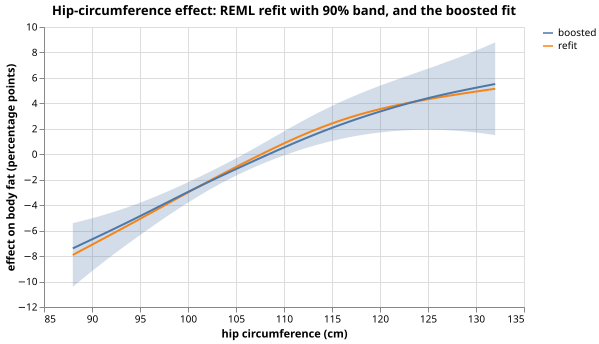

In [6]:
band = alt.Chart(curves).mark_area(opacity=0.25).encode(
    x=alt.X("hipcirc").title("hip circumference (cm)"),
    y=alt.Y("lower").title("effect on body fat (percentage points)"),
    y2="upper",
)
lines = alt.Chart(curves.unpivot(index="hipcirc", on=["refit", "boosted"],
                                 variable_name="fit", value_name="effect")).mark_line().encode(
    x="hipcirc", y="effect", color=alt.Color("fit").title(None))
(band + lines).properties(
    title="Hip-circumference effect: REML refit with 90% band, and the boosted fit",
    width=480, height=280)

The refit's curve rises by
{eval}`round(float(curves["refit"].max() - curves["refit"].min()), 1)`
percentage points of body fat across the observed hip circumferences; the
boosted fit's curve rises by
{eval}`round(float(curves["boosted"].max() - curves["boosted"].min()), 1)`.
The shaded band is the refit's 90% interval.

## Intervals with smoothing-parameter uncertainty: corrected=True

The interval above treats the estimated smoothing parameters as known.
`effects(..., corrected=True)` and `refit.vcov("corrected")` add the
first-order effect of estimating them ([](../methodology/penalized_reml.ipynb) §9).
It widens bands most where a smoothing parameter is poorly determined by the
data. Smoothing parameters at their bound (terms reduced to straight lines)
are treated as known.

In [7]:
plain = refit.effects(grid)["bbs(hipcirc)"]
wide = refit.effects(grid, corrected=True)["bbs(hipcirc)"]
width_ratio = float(np.mean((wide[2] - wide[1]) / (plain[2] - plain[1])))
round(width_ratio, 3)

1.095

For hip circumference the corrected band is on average
{eval}`round(100 * (width_ratio - 1), 1)`% wider than the uncorrected one.

## Predictions: predict()

`refit.predict(newdata)` adds the intercept and every term's effect.
`type="link"` (the default) returns the linear predictor and
`type="response"` the mean; for a Gaussian model they are the same.

In [8]:
first_rows = data.head(5)
pl.DataFrame({
    "DEXfat": first_rows["DEXfat"],
    "refit": np.round(refit.predict(first_rows), 2),
    "boosted": np.round(np.asarray(boosted.predict(newdata=first_rows)).ravel(), 2),
})

DEXfat,refit,boosted
f64,f64,f64
41.68,41.48,41.57
43.29,42.41,43.83
35.41,36.6,35.89
22.79,25.16,25.92
36.42,33.14,33.93


## Choosing the terms: terms=, which= and deselect

By default the refit uses the terms the boosted model selected
(`which="selected"`); `which="all"` refits every term of the formula, and
`terms=[...]` refits a given list. A cross-validated boosted model usually
selects noise terms a few times each. `mb.deselect(model)` removes terms
whose share of the risk reduction is below 1% and refits the boosting path;
its `kept` attribute is the list to pass on.

In [9]:
kept = mb.deselect(boosted).kept
refit_kept = mb.gam_refit(boosted, kept)
pl.DataFrame({"term": list(refit_kept.edf),
              "edf": [round(v, 2) for v in refit_kept.edf.values()]})

term,edf
str,f64
"""bbs(waistcirc)""",1.0
"""bbs(hipcirc)""",2.18
"""bbs(kneebreadth)""",4.26
"""bbs(anthro3a)""",2.36
"""bbs(anthro3b)""",1.0
"""bbs(anthro4)""",1.0


Deselection kept {eval}`len(kept)` of the {eval}`len(refit.edf)` selected
terms. Refitting all terms of a formula written before seeing the data
(`which="all"`) is the only case in which `conditional_on_selection` is
`False`.

## Random effects and new groups: brandom and unseen_levels

A `brandom(g)` term is a Gaussian random effect: one coefficient per level of
`g` with a ridge penalty, whose smoothing parameter is the ratio of the
residual variance to the random-effect variance. The Munich rent data
(3,082 flats in 2003) has the flat's district; a model of rent per
square metre by floor area, year of construction and a district effect.

In [10]:
from mboostrs.datasets import munich_rent

rent = munich_rent()
rent_boosted = mb.gamboost("rentsqm ~ bbs(area) + bbs(yearc) + brandom(district)",
                           data=rent, control=mb.boost_control(500, 0.1))
rent_refit = mb.gam_refit(rent_boosted)
{term: round(edf, 1) for term, edf in rent_refit.edf.items()}

{'bbs(area)': 7.8, 'bbs(yearc)': 4.8, 'brandom(district)': 124.6}

The district effect uses {eval}`round(rent_refit.edf["brandom(district)"], 0)`
effective degrees of freedom for
{eval}`rent["district"].n_unique()` districts: each district's effect is
shrunk towards zero, the average district, and the fewer flats a district
has, the stronger the shrinkage.

A district absent from the refit's training data has no fitted coefficient. By default `effects` and
`predict` raise an error for it; `unseen_levels="zero_effect"` gives it zero
effect, which is the average district, the prediction lme4 makes with
`allow.new.levels = TRUE` and mgcv with `exclude=`. The interval for such a
row is that of the average; a new district's own effect varies around it by
the random-effect standard deviation, which the interval leaves out.

In [11]:
new_flats = {"area": np.array([60, 60]), "yearc": np.array([1960.0, 1960.0]),
             "district": np.array([916, 99999])}
rent_refit.predict(new_flats, unseen_levels="zero_effect").round(3)

array([5.946, 6.813])

### Held learners and unseen levels

`gam_refit(..., unsupported="hold")` keeps a learner the REML refit cannot
represent, such as `btree`, at its boosted contribution while refitting the
other terms. Prediction combines both parts. When a held tree uses a category
absent from fitting, the `unseen_levels` policy applies to its boosted
contribution as well as the refitted effects. `"error"` refuses that category;
`"zero_effect"` follows the boosted predictor's new-level rule and returns a
finite prediction. The held tree's contribution is conditional on its original
boosted fit, so the refit's intervals do not include uncertainty in that tree.

In [12]:
rng = np.random.default_rng(9)
toy_x = rng.normal(size=120)
toy_group = np.repeat(["a", "b", "c", "d"], 30)
toy = pl.DataFrame({"x": toy_x, "g": toy_group,
                    "y": 3 * (toy_group == "d") + toy_x
                         + rng.normal(0, .15, 120)})

toy_fit = mb.gamboost(
    "y ~ btree(g, maxdepth=2, selection=sse) + bols(x)", toy,
    control=mb.boost_control(50))
toy_refit = mb.gam_refit(toy_fit, which="all", unsupported="hold")
novel = pl.DataFrame({"x": [-.5, .5], "g": ["q", "d"]})
print(f"Held term: {toy_refit.held[0]}")
print(toy_refit.predict(novel, unseen_levels="zero_effect").round(3))

Held term: btree(g, maxdepth=2, selection=sse)
[-0.466  3.396]


The first prediction is for the new level `q`, and the second is for
training level `d`. Both include the refitted linear effect; the held tree
contributes according to the declared new-level policy. These numbers
illustrate prediction handling, not an estimate of a new group's random
effect or a performance result on independent data.

## Other response families

The refit supports the families below. Effects are on the scale of the
canonical link, which for Binomial is the log-odds. mboostrs' own boosted
Binomial model is fitted on half the log-odds, so refit effects are twice
the boosted partial effects.

| Family | Effect scale | Scale parameter | Criterion |
|---|---|---|---|
| `Gaussian` | response | estimated | REML |
| `Binomial` | log-odds | 1 | Laplace-approximate REML |
| `Poisson` | log mean | 1 | Laplace-approximate REML |
| `NBinomial` | log mean | 1; $\theta$ estimated | Laplace-approximate REML |
| `GammaReg` | log mean | estimated (gamma shape) | Laplace-approximate REML |
| `CoxPH` | log hazard ratio | 1 | Laplace-approximate REML, Poisson form |

For `NBinomial` the refit estimates the dispersion $\theta$ by the same
criterion, starting from the boosted fit's value, and reports it as
`refit.theta`. A per-row offset of the boosted model (log exposure) is part
of the linear predictor; pass the new rows' offset to `predict(offset=...)`.
Monthly polio cases in the United
States (1970 to 1983) are modelled as Poisson counts with a smooth trend over time.

In [13]:
from mboostrs.datasets import polio

cases = polio()
polio_boosted = mb.gamboost("cases ~ bbs(date)", data=cases, family=mb.Poisson(),
                            control=mb.boost_control(300, 0.1))
polio_refit = mb.gam_refit(polio_boosted)
{"edf": round(polio_refit.edf["bbs(date)"], 2), "link": polio_refit.link,
 "method": polio_refit.convergence["method"]}

{'edf': 11.56, 'link': 'log', 'method': 'outer'}

The trend uses {eval}`round(polio_refit.edf["bbs(date)"], 1)` degrees of
freedom on the log scale of the monthly mean;
`predict(type="response")` returns expected cases per month.

## Surfaces: bspatial and %X%

A `bspatial(a, b)` or `bbs(a) %X% bbs(b)` term is refitted with one smoothing
parameter per variable, as mgcv's `te()`, so the surface can be smooth in one
direction and wiggly in the other. `smoothing` then holds a pair.

In [14]:
surface = mb.gamboost("DEXfat ~ bbs(waistcirc, knots=4) %X% bbs(hipcirc, knots=4)",
                      data=data, control=mb.boost_control(300, 0.1))
surface_refit = mb.gam_refit(surface, which="all")
term = surface_refit.terms[0]
{"edf": round(surface_refit.edf[term], 2),
 "lambda (waist, hip)": tuple(float(f"{v:.3g}") for v in surface_refit.smoothing[term])}

{'edf': 3.0, 'lambda (waist, hip)': (107000.0, 7440.0)}

The waist-by-hip surface uses {eval}`round(surface_refit.edf[term], 1)`
degrees of freedom: close to a plane, which a tensor product with
second-order penalties represents with 3 (the constant is removed by the
sum-to-zero constraint, leaving the two slopes and their product).

## Distributional models: gamlss_refit

`mb.gamlss_refit(model)` applies the refit to a `gamboostLSS` or `glmboostLSS`
model: every distribution parameter keeps its selected terms, all
coefficients are estimated jointly by penalized likelihood, and the
smoothing parameters minimize the Laplace-approximate REML criterion, the
method of mgcv's `gaulss` ([](../methodology/gamlss_reml.ipynb)). `edf`
and `smoothing` are nested by parameter; `effects` and `predict` take a
`parameter=` argument, and `predict(type="response")` returns each parameter
on its natural scale. The motorcycle crash data (head acceleration after an
impact) have a mean and a standard deviation that both change with time.

In [15]:
from mboostrs.datasets import motorcycle

crash = motorcycle()
crash_boosted = mb.gamboostLSS({"mu": "accel ~ bbs(times)", "sigma": "accel ~ bbs(times)"},
                               data=crash, families=mb.GaussianLSS(),
                               control=mb.boost_control(1000, 0.1))
crash_refit = mb.gamlss_refit(crash_boosted, which="all")
times = {"times": np.array([10.0, 20.0, 35.0, 50.0])}
pl.DataFrame({"times (ms)": times["times"],
              "mean (g)": crash_refit.predict(times, parameter="mu", type="response").round(1),
              "sd (g)": crash_refit.predict(times, parameter="sigma", type="response").round(1)})

times (ms),mean (g),sd (g)
f64,f64,f64
10.0,-3.3,1.5
20.0,-114.7,25.6
35.0,24.3,34.5
50.0,-7.9,11.3


The refit uses {eval}`round(crash_refit.edf["mu"]["bbs(times)"], 1)` degrees
of freedom for the mean and {eval}`round(crash_refit.edf["sigma"]["bbs(times)"], 1)`
for the log standard deviation; mgcv's `gaulss` gives 14.49 and 7.67 on the
same data.

A quantity that combines parameters, such as a centile of the response
distribution, needs the correlation between the parameters' estimates.
`crash_refit.draws(newdata, n_draws)` (R: `gamlss_draws(refit, newdata,
n_draws)`) draws every parameter at the new rows from the approximate
posterior of all coefficients; the quantity is computed draw by draw and its
interval taken from the quantiles over the draws. A 90% interval for the 90th centile of acceleration, computed from these draws, is set against $\mu + 1.2816\,\sigma$, the centile under a normal distribution.

In [16]:
# 2,000 draws of mu and sigma at the four times; the centile per draw.
draws = crash_refit.draws(times, 2000, seed=1)
centile_90 = draws["mu"] + 1.2816 * draws["sigma"]
low, middle, high = np.percentile(centile_90, [5, 50, 95], axis=0)
pl.DataFrame({"times (ms)": times["times"], "90th centile (g)": middle.round(1),
              "5%": low.round(1), "95%": high.round(1)})

times (ms),90th centile (g),5%,95%
f64,f64,f64,f64
10.0,-1.3,-2.6,0.2
20.0,-81.7,-95.2,-65.7
35.0,69.0,50.7,90.4
50.0,6.9,-4.6,19.1


## The same analysis in R

The R package calls the same Rust code, so the numbers agree with Python to
rounding. `effects()` returns one data frame per term with `estimate`, `se`,
`lower` and `upper`; `vcov(refit, type = "corrected")` gives the corrected
covariance; the object holds plain R data and can be saved with `saveRDS`.

The distributional refit is `gamlss_refit(fit)`, with `effects(refit,
newdata, parameter = "sigma")` and `predict(refit, newdata, type =
"response")$sigma`.

```r
library(mboostrs)
data("bodyfat", package = "TH.data")
fit <- gamboost(DEXfat ~ bbs(waistcirc) + bbs(hipcirc) + bbs(kneebreadth),
                data = bodyfat)
refit <- gam_refit(fit)
refit                                   # edf and lambda per term
effects(refit, bodyfat[1:5, ])[["bbs(hipcirc)"]]
effects(refit, bodyfat[1:5, ], corrected = TRUE)[["bbs(hipcirc)"]]
predict(refit, bodyfat[1:5, ], type = "response")
logLik(refit); AIC(refit)            # conditional AIC
plot(refit)                             # each effect with its band
```

`mgcv::gam(DEXfat ~ s(hipcirc, bs = "ps", k = 24, m = c(2, 2)) + ...,
method = "REML")` fits the same model on nearly the same basis (mgcv spreads
its knots over a range 0.1% wider); the two agree in edf to within
0.01 and in predictions to within $10^{-3}$.

## Limitations

- **Terms.** `bbs`, `bols` and `brandom` over one variable, each optionally
  with a numeric `by=` column; `bspatial` and `%X%` tensor terms. `bmono`,
  `btree` and `bmrf` terms are refused by name: the first two have no single
  quadratic penalty. The R binding does not yet refit `%X%` terms or `bols`
  on a factor.
- **Families.** Gaussian, Binomial, Poisson, NBinomial, GammaReg and CoxPH.
  For GammaReg the reported scale is the inverse of the gamma shape estimated
  by the REML criterion; mgcv reports a Pearson-type estimate, which differs
  slightly (0.205 here against 0.211 from mgcv) while the fitted curves agree.
- **Corrected intervals.** `corrected=True` adds only the first-order term of
  the smoothing-parameter uncertainty and treats parameters at their bound as
  known; mgcv's `unconditional=TRUE` intervals are wider.
- **Selection.** Intervals are conditional on the terms; when those were
  selected on the same data, the selection's uncertainty is not included.
- **Size.** The refit forms dense matrices of size $P \times P$, with $P$ the
  total number of basis columns; a few thousand columns is the practical
  limit.

## See also

- [](../methodology/penalized_reml.ipynb): the REML criterion, its
  derivation, the algorithm and the intervals.
- [](../methodology/gamlss_reml.ipynb): the joint penalized likelihood and
  Laplace-approximate criterion for distributional models.
- [](inference.ipynb): bootstrap intervals for boosted effects.
- [](../cases/benchmark_insight.ipynb): interval coverage of the refit
  against bootstrap bands and other libraries.